In [ ]:
# ============================================================
# 02_host_preprocessing.ipynb — 환경 설정 (config.py 자동 로드)
# ============================================================
import sys
from pathlib import Path
from sklearn.model_selection import train_test_split

# 프로젝트 루트를 sys.path에 추가 (실행 위치 무관)
for _p in [Path.cwd(), Path.cwd().parent]:
    if (_p / 'config.py').exists():
        sys.path.insert(0, str(_p))
        break

from config import *  # 모든 상수·경로·KPI·시각화 설정·헬퍼 함수 일괄 적용
# ↑ APPROVED_FEATURES(21개), LEAKAGE_COLS, ORDINAL_MAPS, BINARY_COLS, ONEHOT_COLS,
#   TARGET, TARGET_COL, RANDOM_SEED, FEATURES_PATH, PROCESSED_DIR 포함

# ── 피처 데이터 로드 및 Active+Operating 서브셋
df_feat = load_features()
df_ao   = load_features(active_only=True)

available_approved = [f for f in APPROVED_FEATURES if f in df_ao.columns]
leakage_check      = [f for f in LEAKAGE_COLS if f in available_approved]

print(f"✅ 환경 설정 완료 — 승인 피처: {len(available_approved)}개")
print(f"   Features 데이터: {df_feat.shape} | Active+Operating: {len(df_ao):,}건")
if leakage_check:
    print(f"⚠️  누수 피처 감지: {leakage_check}")
else:
    print("   ✅ 데이터 누수 없음")

# 🔧 호스트 관점 — 전처리 및 피처 준비

**목표:** 데이터 누수 없이 모델 학습 데이터를 준비합니다.

**단계:** Active+Oper 서브셋 → 피처 선택 → 결측치 처리 → 인코딩 → log1p 변환 → Train/Test 분리

In [3]:
df_feat = pd.read_csv(FEATURES_PATH)
print(f"Features 데이터: {df_feat.shape}")
mask_ao = (df_feat["refined_status"] == "Active") & (df_feat["operation_status"] == "Operating")
df_ao = df_feat[mask_ao].copy()
print(f"Active+Operating: {len(df_ao):,}건")
available_approved = [f for f in APPROVED_FEATURES if f in df_ao.columns]
leakage_check = [f for f in LEAKAGE_COLS if f in available_approved]
print(f"\n승인 피처 사용 가능: {len(available_approved)}개")
if leakage_check:
    print(f"⚠️ 누수 피처: {leakage_check}")
else:
    print("✅ 데이터 누수 없음")

Features 데이터: (32061, 56)
Active+Operating: 14,399건

승인 피처 사용 가능: 21개
✅ 데이터 누수 없음


In [4]:
df_model = df_ao[available_approved + [TARGET]].copy()
print(f"모델 데이터셋: {df_model.shape}")
missing = df_model.isnull().sum()
print("\n결측치 현황 (>0):")
print(missing[missing > 0] if missing.sum() > 0 else "  없음")

모델 데이터셋: (14399, 22)

결측치 현황 (>0):
  없음


In [5]:
for col in [c for c in df_model.select_dtypes(include="number").columns if c != TARGET]:
    if df_model[col].isnull().any():
        mv = df_model[col].median()
        df_model[col] = df_model[col].fillna(mv)
        print(f"  {col}: 중앙값 {mv:.2f}")
for col in df_model.select_dtypes(include="object").columns:
    if df_model[col].isnull().any():
        mv = df_model[col].mode()[0]
        df_model[col] = df_model[col].fillna(mv)
        print(f"  {col}: 최빈값 '{mv}'")
print(f"결측치 처리 완료. 남은 결측: {df_model.isnull().sum().sum()}")

결측치 처리 완료. 남은 결측: 0


## 2️⃣ 인코딩 및 타겟 변환

In [6]:
label_cols_map = {
    "bedrooms_group": ["스튜디오","1B","2B","3B","4B+"],
    "baths_group": ["0.5","1","1.5","2","2.5","3+"],
    "guests_group": ["1","2","3-4","5-6","7+"],
    "photos_tier": ["하","중하","중상","상"],
    "poi_dist_category": ["초근접","근접","보통","원거리"]
}
for col, order in label_cols_map.items():
    if col in df_model.columns:
        df_model[col] = df_model[col].map({v:i for i,v in enumerate(order)}).fillna(len(order)).astype(int)
        print(f"  {col}: label 인코딩")
for col in ["superhost","instant_book","extra_guest_fee_policy"]:
    if col in df_model.columns:
        df_model[col] = df_model[col].astype(int)
onehot_existing = [c for c in ["room_type","nearest_poi_type_name"] if c in df_model.columns]
df_model = pd.get_dummies(df_model, columns=onehot_existing, drop_first=True)
print(f"\n인코딩 후: {df_model.shape}")

  bedrooms_group: label 인코딩
  baths_group: label 인코딩
  guests_group: label 인코딩
  photos_tier: label 인코딩
  poi_dist_category: label 인코딩

인코딩 후: (14399, 30)


In [7]:
df_model["log_target"] = np.log1p(df_model[TARGET])
print(f"변환 전 skewness: {df_model[TARGET].skew():.3f}")
print(f"변환 후 skewness: {df_model['log_target'].skew():.3f}")
feature_cols = [c for c in df_model.columns if c not in [TARGET, "log_target"]]
X = df_model[feature_cols]; y = df_model["log_target"]; y_orig = df_model[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SEED)
y_train_orig = y_orig.loc[X_train.index]; y_test_orig = y_orig.loc[X_test.index]
print(f"Train: {len(X_train):,} | Test: {len(X_test):,} | 피처: {X.shape[1]}")

변환 전 skewness: 3.167
변환 후 skewness: -1.075
Train: 11,519 | Test: 2,880 | 피처: 29


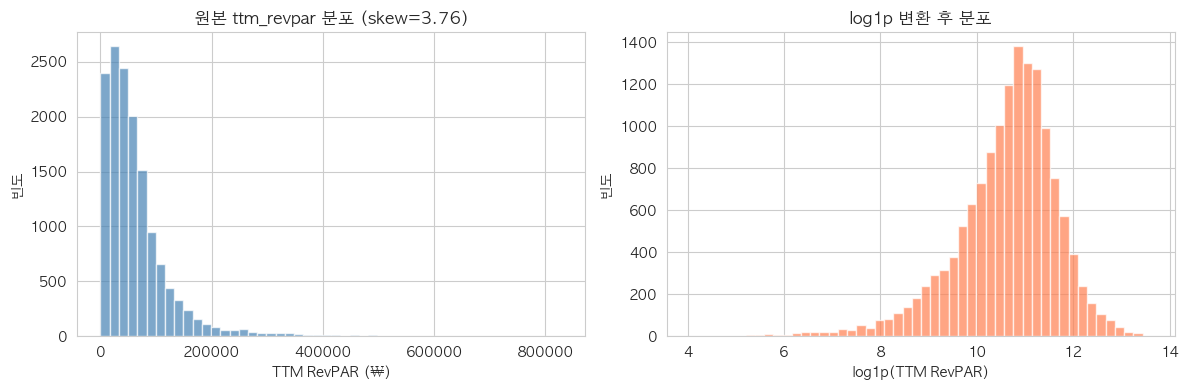

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_orig, bins=50, color="steelblue", alpha=0.7, edgecolor="white")
axes[0].set_title("원본 ttm_revpar 분포 (skew=3.76)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("TTM RevPAR (₩)"); axes[0].set_ylabel("빈도")
axes[1].hist(y, bins=50, color="coral", alpha=0.7, edgecolor="white")
axes[1].set_title("log1p 변환 후 분포", fontsize=12, fontweight="bold")
axes[1].set_xlabel("log1p(TTM RevPAR)"); axes[1].set_ylabel("빈도")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig_02_target_transform.png", dpi=100, bbox_inches="tight")
plt.show()

In [9]:
X_train.to_csv(PROCESSED_DIR / "X_train_host.csv")
X_test.to_csv(PROCESSED_DIR / "X_test_host.csv")
y_train.to_csv(PROCESSED_DIR / "y_train_host_log.csv")
y_test.to_csv(PROCESSED_DIR / "y_test_host_log.csv")
y_train_orig.to_csv(PROCESSED_DIR / "y_train_host_orig.csv")
y_test_orig.to_csv(PROCESSED_DIR / "y_test_host_orig.csv")
print(f"✅ 전처리 완료 — X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"피처 ({X_train.shape[1]}개): {list(X_train.columns)[:5]}...")

✅ 전처리 완료 — X_train: (11519, 29), X_test: (2880, 29)
피처 (29개): ['superhost', 'instant_book', 'bedrooms_group', 'baths_group', 'guests_group']...
